In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import matplotlib.font_manager as fm
import cmcrameri.cm as cm

In [4]:
val_lat = [1,2]
val_lon = [3,4]
np.meshgrid(val_lat, val_lon, indexing="ij")

(array([[1, 1],
        [2, 2]]),
 array([[3, 4],
        [3, 4]]))

In [92]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# cmcrameri.cm.show_cmaps()



In [108]:
cm.lipariS.colors[4]

array([0.320355, 0.358086, 0.480032])

AttributeError: AxesImage.set() got an unexpected keyword argument 'color'

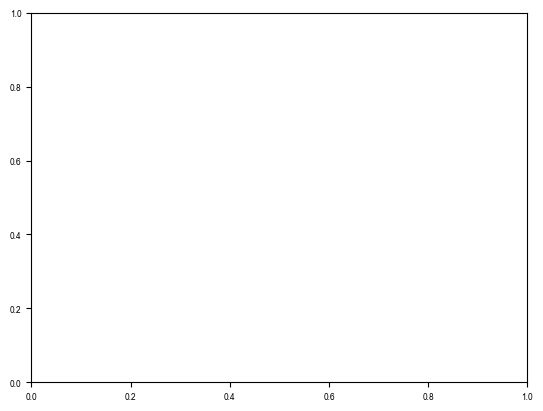

In [113]:
plt.imshow(np.array([[1,1],[1,1]]),color=cm.lipariS.colors[4])

In [135]:
from matplotlib.colors import to_hex

print(to_hex(cm.lipariS.colors[1]))
print(to_hex(cm.lipariS.colors[4]))
print(to_hex(cm.lipariS.colors[6]))
print(to_hex(cm.lipariS.colors[3]))

#fdf5da
#525b7a
#183e61
#e99973


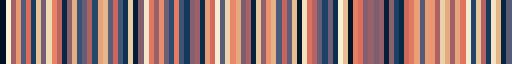

In [133]:
cm.lipariS

In [128]:
cmap = cm.lipariS.colors
# colors = ("#5aa4f7", "#fe9000", "#c95d63")
colors = (cmap[3], cmap[5], cmap[4])
labels = ("tpeak", "tpeak + 15 min", "tpeak + 30 min")


0.35015015015015016
0.6304304304304305
0.9507507507507509


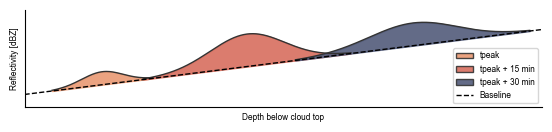

In [129]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# X-axis values
x = np.linspace(0, 10, 1000)

# Sloped baseline
baseline = 0.2 + 0.1 * x


def gaussian(x, mean, std, height):
    """Return a Gaussian curve with a specified height."""
    return height * np.exp(-0.5 * ((x - mean) / std) ** 2)


# Three normal distributions
means = (1.5, 4.3, 7.5)

g1 = gaussian(x, mean=means[0], std=0.4, height=0.2)
g2 = gaussian(x, mean=means[1], std=0.72, height=0.5)
g3 = gaussian(x, mean=means[2], std=0.85, height=0.35)

for mean in means:
    print(baseline[np.argmax(x > mean)])

# Each distribution protrudes vertically from the baseline
curves = (
    baseline + g1,
    baseline + g2,
    baseline + g3,
)



fig, ax = plt.subplots(figsize=(5.501, 1.3))

# Draw the filled distributions and their upper curves
for curve, color, label in zip(curves, colors, labels):
    ind_to_take = curve > baseline + 0.01

    ax.fill_between(
        x[ind_to_take],
        baseline[ind_to_take],
        curve[ind_to_take],
        color=color,
        alpha=0.9,
        label=label,
    )

    ax.plot(
        x[ind_to_take],
        curve[ind_to_take],
        color="#333333",
        linewidth=1,
    )

# Draw the baseline
ax.plot(
    x,
    baseline,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Baseline",
)

ax.set_xlabel("Depth below cloud top")
ax.set_ylabel("Reflectivity [dBZ]")

ax.set_xlim(0, 10)
ax.set_ylim(0, 1.5)
ax.set_xticks([])
ax.set_yticks([])

# Remove the top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ax.legend(loc="lower right")
legend_handles = [
    Patch(
        facecolor=color,
        edgecolor="#333333",
        linewidth=1,
        alpha=0.9,
        label=label,
    )
    for color, label in zip(colors, labels)
]

# Add the dashed baseline entry
legend_handles.append(
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=1,
        linestyle="--",
        label="Baseline",
    )
)

ax.legend(
    handles=legend_handles,
    loc="lower right",
)
plt.tight_layout()
fig.savefig("reflectivity_sketch.pdf",dpi=300)
plt.show()